# Multimodale Maschinenüberwachung

Gemeinsames Notebook für die nacheinander zu bearbeitenden Exercises 16.1–16.4. Aktuell ist ausschließlich 16.1 umgesetzt.

## Exercise 16.1 – Vibration CNN

### Ziel und Anforderungen
Formen, Klassen und Datenqualität des offiziellen synthetischen Datensatzes untersuchen; pro Klasse ein Vibrationssignal und ein Wärmebild mit gemeinsamer Farbskala zeigen. Gepaarter stratifizierter 80/20-Split (Seed 42), je Modalität ein TRAIN-Mittelwert und eine TRAIN-Standardabweichung; Array- und Tensorformen ausgeben. Die vorgegebene `TimeSeriesCNN` mit 32 Features und drei Logits vervollständigen, Dropout/train/eval und Pooling erklären. Mit dem vorgegebenen Adam-/Kreuzentropie-Rahmen 30 Epochen und Batchgröße 16 auf Vibration trainieren. TEST-Confusion-Matrix sowie Kreuztabellen des verborgenen Vibrationslevels mit wahren/vorhergesagten Klassen interpretieren. Verborgene Levels dienen ausschließlich dieser Diagnose.

Quelle: [offizielle Exercise 16.1 und vollständige Codevorlagen](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/3_self_study_session3.html), Abruf 21.11.2026. Ein gemeinsames Notebook ist ausdrücklich vorgeschrieben. Abnahme: alle genannten Tabellen, Formen, zwei erforderlichen Abbildungen und verständliche Interpretation; Notebook und Offline-HTML, ergänzende CSV/JSON-Prüfartefakte. Keine Umsetzung von 16.2–16.4.

Die Kursdaten und das Manuskript stehen unter CC BY-NC-SA 4.0 (Gregor Ehrensperger). Original-JSON unverändert unter `data/raw/sss3_multimodal.json`; Quelle und SHA256 in `data/raw/MULTIMODAL_SOURCE.md`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score
from IPython.display import display
from sessions.ch16.multimodal import (load_multimodal_data, prepare_data, TimeSeriesCNN, train_model, predict_proba, DATA_PATH, RAW_SHA256, NAMES, SEED)
output=Path("outputs/ch16/exercise_16_1")
output.mkdir(parents=True,exist_ok=True)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
ts_data,img_data,labels,levels=load_multimodal_data(str(DATA_PATH))
display(pd.DataFrame([{"Array":name,"Shape":str(a.shape),"Typ":str(a.dtype),"Nicht endlich":int((~np.isfinite(a)).sum())} for name,a in zip(["ts_data","img_data","labels","levels"],[ts_data,img_data,labels,levels])]))
prepared=prepare_data(ts_data,img_data,labels,levels)
# Original frame names remain available for later exercises in this notebook.
ts_train,ts_test=prepared["ts_train"],prepared["ts_test"]
img_train,img_test=prepared["img_train"],prepared["img_test"]
y_train,y_test=prepared["y_train"],prepared["y_test"]
levels_train,levels_test=prepared["levels_train"],prepared["levels_test"]
ts_train_norm,ts_test_norm=prepared["ts_train_norm"],prepared["ts_test_norm"]
img_train_norm,img_test_norm=prepared["img_train_norm"],prepared["img_test_norm"]
ts_train_tensor,ts_test_tensor=prepared["ts_train_tensor"],prepared["ts_test_tensor"]
img_train_tensor,img_test_tensor=prepared["img_train_tensor"],prepared["img_test_tensor"]
y_train_tensor=prepared["y_train_tensor"]
ts_mean,ts_std=prepared["ts_mean"],prepared["ts_std"]
img_mean,img_std=prepared["img_mean"],prepared["img_std"]
class_counts=pd.DataFrame({"Klasse":NAMES,"Gesamt":np.bincount(labels,minlength=3),"TRAIN":np.bincount(y_train,minlength=3),"TEST":np.bincount(y_test,minlength=3)})
display(class_counts)
class_counts.to_csv(output/"class_counts.csv",index=False)


,Array,Shape,Typ,Nicht endlich
0,ts_data,"(500, 80)",float64,0
1,img_data,"(500, 32, 32)",float64,0
2,labels,"(500,)",int64,0
3,levels,"(500, 2)",int64,0


,Klasse,Gesamt,TRAIN,TEST
0,Normal,240,192,48
1,Warning,185,148,37
2,Critical,75,60,15


### Ein Beispiel je Gesundheitsklasse
Als reproduzierbare Illustration wird die erste TRAIN-Beobachtung je Klasse gewählt, nicht ein nachträglich besonders deutliches Beispiel. Drei Beispiele repräsentieren nicht die gesamte Streuung. Alle Bilder verwenden das globale Temperaturintervall 11,4–68,6 °C ausschließlich zur Darstellung; es fließt nicht in die Vorverarbeitung ein. Vibrationsamplitude ohne spezifizierte physikalische Einheit, Zeit als Abtastindex.

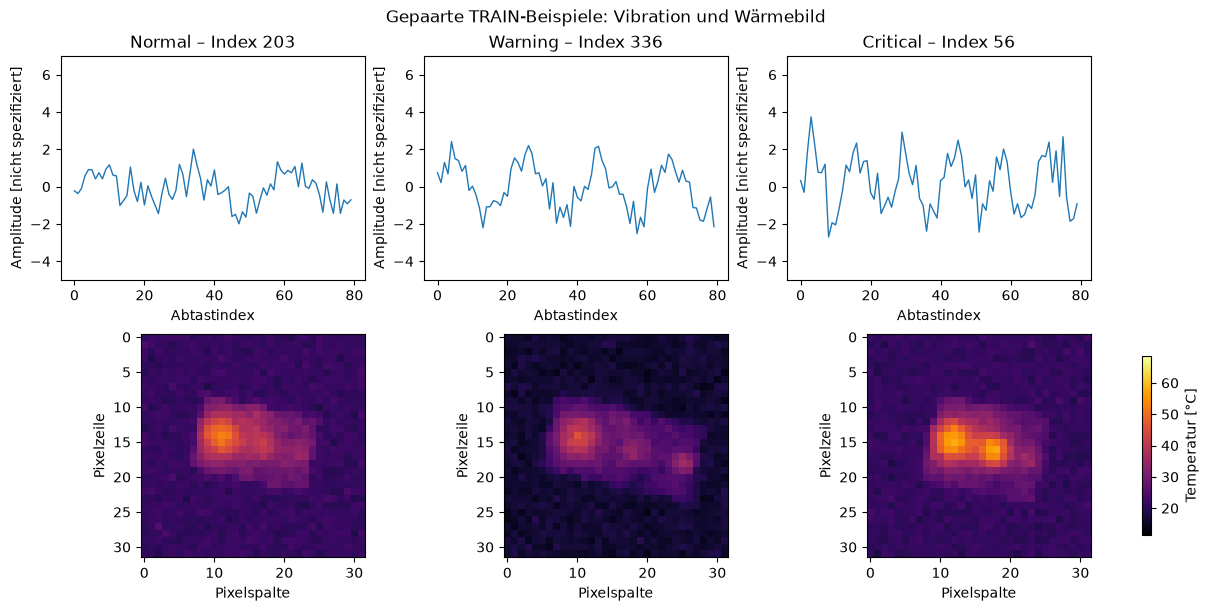

In [2]:
fig,axes=plt.subplots(2,3,figsize=(12,6),layout="constrained")
examples=[]
for status,name in enumerate(NAMES):
    local_index=np.flatnonzero(y_train==status)[0]
    index=int(prepared["train_indices"][local_index])
    examples.append({"Klasse":name,"Index_0basiert":index})
    axes[0,status].plot(np.arange(80),ts_data[index],lw=1)
    axes[0,status].set(title=f"{name} – Index {index}",xlabel="Abtastindex",ylabel="Amplitude [nicht spezifiziert]",ylim=(-5,7))
    image=axes[1,status].imshow(img_data[index],cmap="inferno",vmin=img_data.min(),vmax=img_data.max(),origin="upper")
    axes[1,status].set(xlabel="Pixelspalte",ylabel="Pixelzeile")
fig.colorbar(image,ax=axes[1,:],label="Temperatur [°C]",shrink=.8)
fig.suptitle("Gepaarte TRAIN-Beispiele: Vibration und Wärmebild")
fig.savefig(output/"01_class_examples.png",dpi=150,bbox_inches="tight")
plt.show()
pd.DataFrame(examples).to_csv(output/"example_indices.csv",index=False)


Das Wärmebild zeigt das Gehäuse und warme Bereiche der Bauteile: Motor links, Getriebe mittig, Lager rechts sowie Steuerung oben. Unten liegt der kühlere Lufteinlass. Diese Zuordnung stammt aus der Simulationserklärung; Lage und Drehung variieren, eine einzelne helle Stelle ist kein Beweis für ein bestimmtes Bauteil. Temperatur hängt auch von der Last ab. Ein thermisches Problem betrifft Getriebe/Lager relativ zur am Motor sichtbaren Last. Im gezeigten Warning-Beispiel ist das Bild insgesamt kühler als im Normal-Beispiel; beim Critical-Beispiel fällt ein stärkerer warmer Bereich in Gehäusemitte auf. Die Gesamthelligkeit ordnet die Klassen also nicht einfach. Die Beispiele zeigen Unterschiede, begründen aber keine sichere Trennung per Augenmaß. Benachbarte Vibrationslevel überlappen.

### Vorverarbeitung und CNN
Alle Modalitäten, Labels und Diagnoselevel behalten dieselben Indizes. Je Modalität wird über **alle TRAIN-Werte** ein Mittelwert und eine Standardabweichung (ddof=0) berechnet; dieselben zwei Zahlen werden auf TEST angewendet. Kein bildweises oder zeitpunktweises Fitten, keine TEST-Statistik zur Skalierung.

Ein 1D-CNN verschiebt lernbare Filter entlang des Signals und erkennt lokale Muster. Zwei Blöcke Conv1d (1→16→32, Kernel 5, same) + ReLU + MaxPool1d(2) verkürzen 80→40→20 Werte. AvgPool1d(20) mittelt danach je Kanal zu einem Wert; Flatten und Linear(32,32)+ReLU ergeben 32 Features, Dropout(0,3) und Linear(32,3) drei Logits. Kein Softmax vor CrossEntropyLoss.

Dropout setzt im Training zufällig einzelne Aktivierungen mit Wahrscheinlichkeit 0,3 auf null und skaliert die übrigen mit 1/0,7. Das erschwert ein zu starkes Verlassen auf einzelne Aktivierungen und kann Überanpassung begrenzen, garantiert sie aber nicht. `model.train()` aktiviert dieses Verhalten. `model.eval()` deaktiviert es: Bei der Vorhersage sollen alle gelernten Aktivierungen stabil verwendet werden. `no_grad()` verhindert zusätzlich die unnötige Gradientenberechnung; es ersetzt `eval()` nicht.

Max Pooling behält den größten Wert eines Fensters und betont starke lokale Aktivierungen; Average Pooling bildet den Mittelwert. Hier verdichtet das abschließende Average Pooling die 20 verbleibenden Positionen zu einem Wert je Kanal. Quellen, gelesen 21.11.2026: [Dropout](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Dropout.html), [AvgPool1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.AvgPool1d.html), [MaxPool1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.MaxPool1d.html).

In [3]:
shape_rows=[]
for name in ["ts_train","ts_test","img_train","img_test","y_train","y_test","levels_train","levels_test","ts_train_norm","ts_test_norm","img_train_norm","img_test_norm","ts_train_tensor","ts_test_tensor","img_train_tensor","img_test_tensor","y_train_tensor"]:
    shape_rows.append({"Name":name,"Shape":str(tuple(prepared[name].shape))})
shapes=pd.DataFrame(shape_rows)
display(shapes)
shapes.to_csv(output/"shapes.csv",index=False)
scaling={k:prepared[k] for k in ["ts_mean","ts_std","img_mean","img_std"]}
display(pd.DataFrame([scaling]))
(output/"scaling.json").write_text(json.dumps(scaling,indent=2),encoding="utf-8")
print("features:",tuple(TimeSeriesCNN().features(ts_train_tensor[:4]).shape))
print("logits:",tuple(TimeSeriesCNN()(ts_train_tensor[:4]).shape))
assert TimeSeriesCNN().features(ts_train_tensor[:4]).shape==(4,32)
assert TimeSeriesCNN()(ts_train_tensor[:4]).shape==(4,3)


,Name,Shape
0,ts_train,"(400, 80)"
1,ts_test,"(100, 80)"
2,img_train,"(400, 32, 32)"
3,img_test,"(100, 32, 32)"
4,y_train,"(400,)"
5,y_test,"(100,)"
6,levels_train,"(400, 2)"
7,levels_test,"(100, 2)"
8,ts_train_norm,"(400, 80)"
9,ts_test_norm,"(100, 80)"


,ts_mean,ts_std,img_mean,img_std
0,0.101644,1.220889,22.671155,5.979884


features: (4, 32)
logits: (4, 3)


### Training und TEST-Auswertung
Der offizielle wiederverwendbare Trainingsrahmen nutzt Adam mit Standard-Lernrate 0,001, CrossEntropyLoss, Batchgröße 16 und genau 30 Epochen. Ein fester CPU-Lauf mit Seed 42 und einem Rechenthread; keine Hyperparametersuche oder TEST-basierte Auswahl. Der Seed wird direkt vor der Modellinitialisierung erneut gesetzt, damit vorherige Shape-Prüfungen das Training nicht verändern. Wärmebilder und verborgene Levels gehen nicht in das Modell ein.

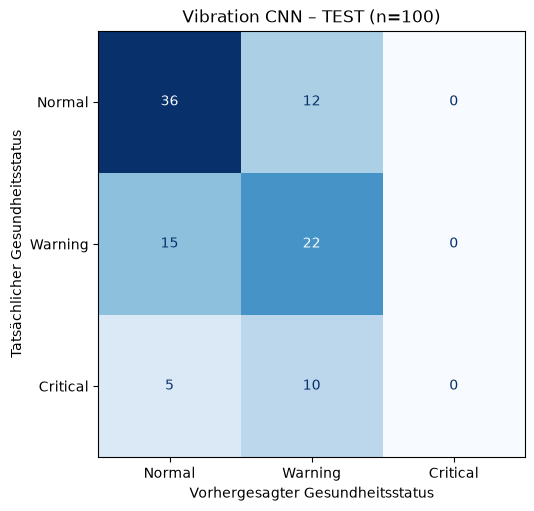

{'accuracy': 0.58, 'correct': 58, 'test': 100, 'seed': 42, 'epochs': 30, 'batch_size': 16, 'parameters': 3843, 'torch': '2.9.1+cpu', 'cpu_threads': 1, 'raw_sha256': '3f7a7e52bd2b0efd0f3af43b07efa2c05620589a09d67d82519598f6f99d6d03'}


In [4]:
torch.manual_seed(SEED)
ts_loader=DataLoader(TensorDataset(ts_train_tensor,y_train_tensor),batch_size=16,shuffle=True)
model_ts=train_model(TimeSeriesCNN(),ts_loader,epochs=30)
ts_test_probs=predict_proba(model_ts,ts_test_tensor)
ts_pred=ts_test_probs.argmax(axis=1)
cm=confusion_matrix(y_test,ts_pred,labels=[0,1,2])
fig,ax=plt.subplots(figsize=(6,5),layout="constrained")
ConfusionMatrixDisplay.from_predictions(y_test,ts_pred,labels=[0,1,2],display_labels=NAMES,ax=ax,cmap="Blues",colorbar=False)
ax.set(title="Vibration CNN – TEST (n=100)",xlabel="Vorhergesagter Gesundheitsstatus",ylabel="Tatsächlicher Gesundheitsstatus")
fig.savefig(output/"02_confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()
predictions=pd.DataFrame({"Index_0basiert":prepared["test_indices"],"Ist":y_test,"Vorhersage":ts_pred,**{f"p_{name}":ts_test_probs[:,i] for i,name in enumerate(NAMES)}})
predictions.to_csv(output/"predictions.csv",index=False)
pd.DataFrame(cm,index=NAMES,columns=NAMES).to_csv(output/"confusion_matrix.csv")
summary={"accuracy":float(accuracy_score(y_test,ts_pred)),"correct":int((ts_pred==y_test).sum()),"test":len(y_test),"seed":SEED,"epochs":30,"batch_size":16,"parameters":sum(p.numel() for p in model_ts.parameters()),"torch":torch.__version__,"cpu_threads":torch.get_num_threads(),"raw_sha256":RAW_SHA256}
(output/"summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
print(summary)


### Was lässt sich aus Vibration lernen?
Die verborgenen Levels werden erst zur Diagnose mit den Ergebnissen verglichen. Laut Definition hängt Gesundheit von beiden Modalitäten ab: Bei Vibrationslevel 0/1 kann die thermische Stufe zu Normal, Warning oder Critical führen. Bei Vibrationslevel 2 ergeben thermische Stufen 0/1/2 Warning/Critical/Critical. Aus Vibration allein ist diese thermische Information nicht eindeutig verfügbar. Eine Critical-Vorhersage wäre deshalb nicht grundsätzlich unmöglich, aber keine sichere Diagnose nur aus diesem Signal.

In [5]:
def levels_vs_status(level: np.ndarray,pred: np.ndarray,level_name: str)->pd.DataFrame:
    """Official diagnostic helper; uses TEST truth, never training inputs."""
    return pd.concat([pd.crosstab(level,y_test,colnames=["status"]),pd.crosstab(level,pred,colnames=["status"])],axis=1,keys=["true health status","predicted health status"]).rename_axis(level_name)
vibration_comparison=levels_vs_status(levels_test[:,1],ts_pred,"vibration level")
display(vibration_comparison)
vibration_comparison.to_csv(output/"vibration_levels_vs_status.csv")
print("Vorhersagehäufigkeiten:",dict(zip(NAMES,np.bincount(ts_pred,minlength=3).tolist())))
split=pd.DataFrame({"Index_0basiert":np.r_[prepared["train_indices"],prepared["test_indices"]],"Split":["TRAIN"]*400+["TEST"]*100})
split.to_csv(output/"split.csv",index=False)


true health status        predicted health status    
status                           0   1  2                       0   1
vibration level                                                      
0                               33  12  5                      50   0
1                               15  12  2                       6  23
2                                0  13  8                       0  21

Vorhersagehäufigkeiten: {'Normal': 56, 'Warning': 44, 'Critical': 0}


### Interpretation und Grenzen
Das CNN klassifiziert **58/100 TEST-Beobachtungen korrekt (Accuracy 0,58)**. Normal wird bei 36/48, Warning bei 22/37 erkannt. Alle 15 Critical-Fälle werden übersehen: fünf als Normal, zehn als Warning. Das Modell sagt insgesamt 56-mal Normal und 44-mal Warning voraus, niemals Critical.

Die Kreuztabelle zeigt: Vibrationslevel 0 wird immer als Normal eingestuft (50 Fälle), Level 2 immer als Warning (21 Fälle); bei Level 1 entstehen sechs Normal- und 23 Warning-Vorhersagen. Das passt zu einem überwiegend nach Vibrationsniveau trennenden Modell, ist aber kein Beweis für eine vollständig gelernte Level-Erkennung. Die wahren Klassen bleiben innerhalb jedes Levels gemischt. Bei Level 2 stehen beispielsweise 13 Warning- acht Critical-Fällen gegenüber. Dass hier keine Critical-Vorhersage entsteht, ist angesichts fehlender thermischer Information und seltener Critical-Fälle plausibel; es ist weder zwingend für jedes CNN noch für Sicherheitsüberwachung ausreichend. Gesundheitsunterschiede durch thermische Zustände bleiben mit diesem Input nicht eindeutig zugänglich. Die kleine synthetische Stichprobe und ein einziger fester Split erlauben keine allgemeine Aussage über reale Maschinen. Keine externe Validierung, keine Optimierung nach TEST-Ergebnissen und kein Nachweis über Overfitting ohne gesonderte Validierungsdaten. Numerische Wiederholbarkeit gilt für die dokumentierte CPU-Umgebung, nicht automatisch bitweise für andere Plattformen.

KI-Unterstützung: Codex las die Vorgaben, ergänzte das CNN und die Auswertung und führte technische Prüfungen aus. Studentischer Human Review steht aus. **AWAITING HUMAN REVIEW.**

## Exercise 16.2 – Thermal Image CNN

### Ziel und offizielle Anforderungen
Die Klasse `ThermalCNN(in_channels=1)` gemäß Tabelle 16.3 vervollständigen, Feature-/Logitformen prüfen, mit dem bestehenden Trainingsrahmen 30 Epochen trainieren und die TEST-Confusion-Matrix darstellen. Thermisches Diagnoselevel mit wahrem und vorhergesagtem Gesundheitsstatus vergleichen und die Grenzen einer einzelnen Modalität erklären.

Quelle: [offizielle Exercise 16.2, Milestone 2 und vollständige Codevorlagen](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/3_self_study_session3.html), erneut gelesen am 21.11.2026. Abnahme: exakte Schichten, Shapes (4,64)/(4,3), unveränderter Split und TRAIN-Skalierung, tatsächliches Training/TEST-Matrix, Thermal-Level-Tabelle und begründete Interpretation. Notebook und HTML mit ergänzenden Ergebnisdateien; keine Fusion und keine zusätzliche Architektur.

16.1 ist wissenschaftlich freigegeben und integriert. Der obige Abschnitt bleibt als ursprünglicher Entwicklungsstand vollständig erhalten, einschließlich seiner damaligen Statusangaben. Aktueller Reviewstatus steht in den jeweiligen Reviewdateien. Hier werden ausschließlich die bestehenden Bildtensoren, Labels, Split-Indizes und TRAIN-Skalare wiederverwendet; versteckte Levels bleiben Diagnosegrößen.

### Methode
Die 3×3-Filter einer 2D-Faltung suchen lokale Bildmuster, beispielsweise Kanten oder warme Bereiche. ReLU lässt positive Aktivierungen bestehen. Max Pooling halbiert die räumlichen Abmessungen: (1,32,32) → (16,32,32) → (16,16,16) → (32,16,16) → (32,8,8). Flatten ergibt 2.048 Werte; Linear(2048,64)+ReLU und Dropout(0,3) liefern den Featurevektor, Linear(64,3) drei Logits. Dropout und train/eval funktionieren wie in 16.1 beschrieben. `in_channels=1` bezeichnet die eine Temperatur je Pixel; der Parameter bleibt wie vorgegeben erhalten.

Vorverarbeitung und Training bleiben gleich: 400 TRAIN-/100 TEST-Beobachtungen, dieselben gepaarten Indizes und ein einziger TRAIN-Mittelwert/eine TRAIN-Standardabweichung für alle Bildpixel. Adam (lr 0,001), CrossEntropyLoss, Batch 16 und 30 Epochen. Seed 42 wird unmittelbar vor Initialisierung gesetzt, damit vorherige Shape-Prüfungen das Training nicht beeinflussen. Keine TEST-Auswahl, keine Suche, keine zusätzlichen Eingaben.

In [6]:
from sessions.ch16.thermal import ThermalCNN
output_img=Path("outputs/ch16/exercise_16_2")
output_img.mkdir(parents=True,exist_ok=True)
print("Bildtensoren:",tuple(img_train_tensor.shape),tuple(img_test_tensor.shape))
print("Features:",tuple(ThermalCNN().features(img_train_tensor[:4]).shape))
print("Logits:",tuple(ThermalCNN()(img_train_tensor[:4]).shape))
assert ThermalCNN().features(img_train_tensor[:4]).shape==(4,64)
assert ThermalCNN()(img_train_tensor[:4]).shape==(4,3)


Bildtensoren: (400, 1, 32, 32) (100, 1, 32, 32)
Features: (4, 64)
Logits: (4, 3)


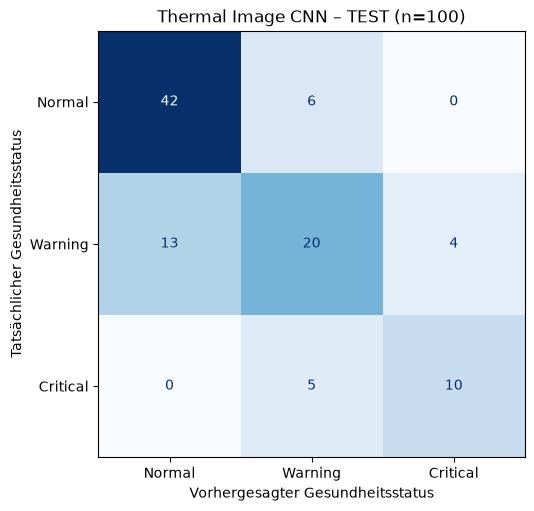

{'accuracy': 0.72, 'correct': 72, 'test': 100, 'seed': 42, 'epochs': 30, 'batch_size': 16, 'parameters': 136131, 'torch': '2.9.1+cpu', 'cpu_threads': 1, 'raw_sha256': '3f7a7e52bd2b0efd0f3af43b07efa2c05620589a09d67d82519598f6f99d6d03'}


In [7]:
torch.manual_seed(SEED)
img_loader=DataLoader(TensorDataset(img_train_tensor,y_train_tensor),batch_size=16,shuffle=True)
model_img=train_model(ThermalCNN(),img_loader,epochs=30)
img_test_probs=predict_proba(model_img,img_test_tensor)
img_pred=img_test_probs.argmax(axis=1)
img_cm=confusion_matrix(y_test,img_pred,labels=[0,1,2])
fig,ax=plt.subplots(figsize=(6,5),layout="constrained")
ConfusionMatrixDisplay.from_predictions(y_test,img_pred,labels=[0,1,2],display_labels=NAMES,ax=ax,cmap="Blues",colorbar=False)
ax.set(title="Thermal Image CNN – TEST (n=100)",xlabel="Vorhergesagter Gesundheitsstatus",ylabel="Tatsächlicher Gesundheitsstatus")
fig.savefig(output_img/"01_confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()
pd.DataFrame({"Index_0basiert":prepared["test_indices"],"Ist":y_test,"Vorhersage":img_pred,**{f"p_{name}":img_test_probs[:,i] for i,name in enumerate(NAMES)}}).to_csv(output_img/"predictions.csv",index=False)
pd.DataFrame(img_cm,index=NAMES,columns=NAMES).to_csv(output_img/"confusion_matrix.csv")
img_summary={"accuracy":float(accuracy_score(y_test,img_pred)),"correct":int((img_pred==y_test).sum()),"test":len(y_test),"seed":SEED,"epochs":30,"batch_size":16,"parameters":sum(p.numel() for p in model_img.parameters()),"torch":torch.__version__,"cpu_threads":torch.get_num_threads(),"raw_sha256":RAW_SHA256}
(output_img/"summary.json").write_text(json.dumps(img_summary,indent=2),encoding="utf-8")
print(img_summary)


In [8]:
thermal_comparison=levels_vs_status(levels_test[:,0],img_pred,"thermal level")
display(thermal_comparison)
thermal_comparison.to_csv(output_img/"thermal_levels_vs_status.csv")
print("Vorhersagehäufigkeiten:",dict(zip(NAMES,np.bincount(img_pred,minlength=3).tolist())))
# Identische Skalarwerte und Indizes für transparente Nachprüfung speichern.
(output_img/"scaling.json").write_text(json.dumps(scaling,indent=2),encoding="utf-8")
split.to_csv(output_img/"split.csv",index=False)


true health status         predicted health status        
status                         0   1   2                       0   1   2
thermal level                                                           
0                             48  13   0                      54   7   0
1                              0  24   5                       1  24   4
2                              0   0  10                       0   0  10

Vorhersagehäufigkeiten: {'Normal': 55, 'Warning': 31, 'Critical': 14}


### Interpretation und Grenzen
Das Modell erkennt **72/100 TEST-Beobachtungen korrekt (Accuracy 0,72)**: Normal 42/48, Warning 20/37, Critical 10/15. Sechs Normal-Fälle werden als Warning eingestuft; 13 Warning-Fälle als Normal und vier als Critical. Fünf Critical-Fälle werden als Warning übersehen. Gegenüber 16.1 (58/100) sind hier 14 zusätzliche Vorhersagen korrekt, ohne daraus statistische Signifikanz oder allgemeine Überlegenheit abzuleiten.

Bei Thermal-Level 0 stehen 48 Normal- und 13 Warning-Fälle; das Modell sagt 54-mal Normal und siebenmal Warning voraus. Bei Level 1 sind 24 Fälle Warning und fünf Critical; vorhergesagt werden einmal Normal, 24-mal Warning und viermal Critical. Alle zehn Thermal-Level-2-Fälle sind tatsächlich Critical und werden hier korrekt erkannt. Die verbleibenden Verwechslungen zeigen, dass die thermischen Bilder die vollständige Gesundheitsklasse nicht eindeutig festlegen. Diese kleine Kreuztabelle beweist keine perfekte Erkennung des verborgenen thermischen Levels. Laut Kursdefinition ist der Gesundheitsstatus bei Thermal-Level 0 je nach Vibration Normal oder Warning und bei Thermal-Level 1 Warning oder Critical. Erst Thermal-Level 2 ist immer Critical. Auch ein gut erkanntes thermisches Niveau bestimmt damit nicht in jedem Fall den vollständigen Gesundheitsstatus. Das Bild enthält zudem Last- und Lagevariation; Helligkeit allein reicht nicht.

Der Vergleich mit 16.1 gilt nur für denselben kleinen synthetischen TEST-Split. Keine universelle Überlegenheit einer Modalität, externe Validierung oder Sicherheitseignung behauptet. Keine nachträgliche Optimierung und kein Overfitting-Nachweis ohne Validierungsdaten. Keine Fusion implementiert.

KI-Unterstützung: Codex ergänzte 16.2 und führte die dokumentierten technischen Prüfungen durch. Studentischer Review für 16.2 steht aus: **AWAITING HUMAN REVIEW**.

**Tatsächlicher CI-Plattformbefund:** Auf zwei GitHub-Runnern erreichte dasselbe Thermal-CNN 70/100 bzw. 73/100 statt lokal 72/100. Je Runner waren zwei unabhängige frische Ausführungen einschließlich aller Wahrscheinlichkeiten exakt gleich. Gegenüber den gespeicherten 16.1-Vorhersagen unterschieden sich null bzw. eine Klasse. Die Ergebnisse sind also innerhalb der jeweiligen Umgebung wiederholbar, nicht plattformübergreifend identisch. Diese beiläufigen CI-Beobachtungen sind keine geplante Wiederholungsstudie oder statistische Unsicherheitsschätzung. Keine Auswahl des besten Resultats und keine Modelländerung daraus abgeleitet. Alle oben dargestellten Matrizen beziehen sich auf den dokumentierten lokalen Lauf.

## Exercise 16.3 – Early and Late Fusion

### Ziel und Anforderungen
Vibration und Wärmebild mit den beiden offiziell vorgegebenen Verfahren kombinieren: Early Fusion mit `as_image_channel`, zweikanaliger `ThermalCNN`, 30 Epochen und TEST-Confusion-Matrix; Late Fusion als ungewichtetes Mittel der vorhandenen Klassenwahrscheinlichkeiten mit eigener TEST-Matrix. Vier Modelle auf denselben TEST-Beobachtungen vergleichen. Die ergänzende Vergleichstabelle nennt Accuracy, korrekte Beobachtungen und korrekt erkannte Critical-Fälle.

Quelle: [offizielle Exercise 16.3, „Combine the raw inputs, combine the predictions“, Milestone 3 mit Codevorlage](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/3_self_study_session3.html), erneut gelesen am 21.11.2026. Abnahme: Shapes (400,2,32,32)/(100,2,32,32), korrektes Padding/Kanalreihenfolge, unveränderter Split/TRAIN-Vorverarbeitung, vorgegebene Trainingsparameter, korrekte Mittelung/Argmax, Matrizen und begründeter Vergleich. Keine Fusion-Optimierung und keine Umsetzung von 16.4.

Die genehmigten Abschnitte 16.1 und 16.2 bleiben einschließlich ihrer historischen Ausgaben unverändert. **Die folgende Vergleichstabelle und alle vier Matrizen stammen dagegen gemeinsam aus der aktuellen vollständigen Notebook-Ausführung.** Sie verwenden nur deren `ts_test_probs` und `img_test_probs`, nicht die historischen CSV-Vorhersagen. So werden Ergebnisse verschiedener Umgebungen nicht vermischt.

### Early Fusion: Eingaben verbinden
Die 80 bereits mit TRAIN-Werten standardisierten Vibrationswerte werden auf 1.024 Werte mit Nullen ergänzt und zu 32×32 umgeformt. Wir stapeln zuerst das Wärmebild, danach den künstlichen Vibrationskanal. Der Klassifikator kann beide Kanäle bereits in den Faltungsfiltern gemeinsam verarbeiten.

Die Darstellung ist technisch passend, aber zeitlich unnatürlich: Am Zeilenumbruch werden direkt aufeinanderfolgende Zeitpunkte getrennt; vertikale Bildnachbarn liegen 32 Zeitpunkte auseinander. Außerdem enthalten 944/1.024 Positionen nur Padding. Diese räumliche Anordnung besitzt keine physikalische Bildbedeutung. Es handelt sich um den Kursansatz, nicht um eine als optimal nachgewiesene Repräsentation.

`ThermalCNN(in_channels=2)` bleibt ansonsten unverändert (136.275 Parameter). Wie zuvor: Adam lr 0,001, CrossEntropyLoss, Batch 16, genau 30 Epochen; Seed 42 direkt vor Initialisierung. Es werden nur TRAIN-Tensoren verwendet, keine Diagnoselevels.

In [9]:
from sessions.ch16.fusion import as_image_channel, mean_probabilities
output_fusion=Path("outputs/ch16/exercise_16_3")
output_fusion.mkdir(parents=True,exist_ok=True)
early_train_tensor=torch.cat([img_train_tensor,as_image_channel(ts_train_norm)],dim=1)
early_test_tensor=torch.cat([img_test_tensor,as_image_channel(ts_test_norm)],dim=1)
assert early_train_tensor.shape==(400,2,32,32)
assert early_test_tensor.shape==(100,2,32,32)
print("Early TRAIN/TEST:",tuple(early_train_tensor.shape),tuple(early_test_tensor.shape))
torch.manual_seed(SEED)
early_loader=DataLoader(TensorDataset(early_train_tensor,y_train_tensor),batch_size=16,shuffle=True)
model_early=train_model(ThermalCNN(in_channels=2),early_loader,epochs=30)
early_test_probs=predict_proba(model_early,early_test_tensor)
early_pred=early_test_probs.argmax(axis=1)
print("Early Accuracy:",accuracy_score(y_test,early_pred))


Early TRAIN/TEST: (400, 2, 32, 32) (100, 2, 32, 32)


Early Accuracy: 0.91


### Late Fusion: Vorhersagen verbinden
Für jede TEST-Beobachtung werden die drei Wahrscheinlichkeiten der beiden schon trainierten Einzelmodelle gemittelt: p_late = (p_vibration + p_thermal)/2. Danach entscheidet der größte Wert. Beide Arrays stammen aus dieser Ausführung und besitzen dieselben TEST-Indizes und dieselbe Klassenreihenfolge Normal/Warning/Critical.

Hier wird kein neues Modell trainiert. Es gibt weder gelernte Gewichte noch Kalibrierung oder TEST-basierte Gewichtswahl. Die Modalitäten lernen unabhängig voneinander; erst ihre fertigen Vorhersagen treffen zusammen. Ein unsicheres oder für eine Klasse schwaches Modell kann die Vorhersage des anderen abschwächen. Deshalb muss eine solche Kombination nicht besser sein. Ob das hier zutrifft, zeigt erst die Auswertung.

In [10]:
assert ts_test_probs.shape==img_test_probs.shape==(100,3)
late_test_probs=mean_probabilities(ts_test_probs,img_test_probs)
late_pred=late_test_probs.argmax(axis=1)
print("Late Accuracy:",accuracy_score(y_test,late_pred))


Late Accuracy: 0.79


### Vier Modelle aus demselben Lauf vergleichen
Alle folgenden Werte verwenden denselben TEST-Split und die in dieser Ausführung trainierten Einzelmodelle. Die ursprünglichen Ausgaben in den freigegebenen Abschnitten sind historische Referenzen. Zeilen der Matrizen: tatsächlich; Spalten: vorhergesagt. „Critical erkannt“ zählt die korrekt vorhergesagten Critical-Fälle, nicht alle Critical-Vorhersagen.

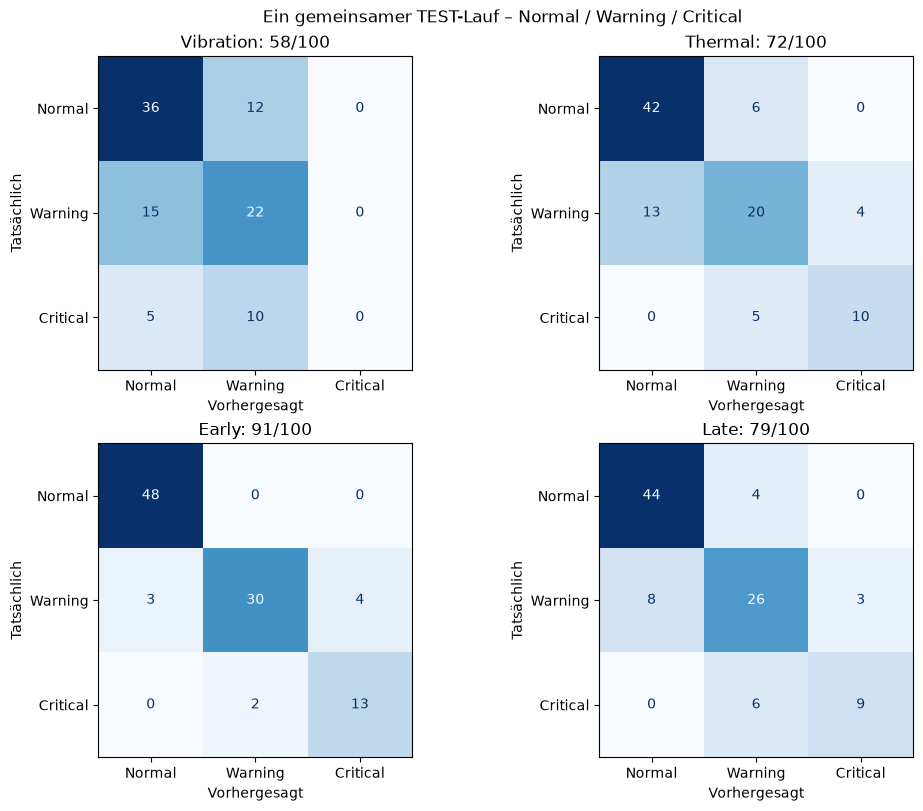

,Modell,Accuracy,Korrekt,Critical erkannt,Critical TEST
0,Vibration,0.58,58,0,15
1,Thermal,0.72,72,10,15
2,Early,0.91,91,13,15
3,Late,0.79,79,9,15


664

In [11]:
methods={"Vibration":(ts_test_probs,ts_pred),"Thermal":(img_test_probs,img_pred),"Early":(early_test_probs,early_pred),"Late":(late_test_probs,late_pred)}
rows=[];matrix_rows=[]
prediction_rows={"Index_0basiert":prepared["test_indices"],"Ist":y_test}
fig,axes=plt.subplots(2,2,figsize=(10,8),layout="constrained")
for ax,(name,(probs,pred)) in zip(axes.flat,methods.items()):
    matrix=confusion_matrix(y_test,pred,labels=[0,1,2])
    correct=int((y_test==pred).sum())
    rows.append({"Modell":name,"Accuracy":correct/len(y_test),"Korrekt":correct,"Critical erkannt":int(matrix[2,2]),"Critical TEST":int((y_test==2).sum())})
    for i in range(3):
        for j in range(3):
            matrix_rows.append({"Modell":name,"Ist":i,"Vorhersage":j,"Anzahl":int(matrix[i,j])})
    prediction_rows[name+"_Vorhersage"]=pred
    for c in range(3):prediction_rows[f"{name}_p{c}"]=probs[:,c]
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1,2],display_labels=NAMES,ax=ax,cmap="Blues",colorbar=False)
    ax.set(title=f"{name}: {correct}/100",xlabel="Vorhergesagt",ylabel="Tatsächlich")
fig.suptitle("Ein gemeinsamer TEST-Lauf – Normal / Warning / Critical")
fig.savefig(output_fusion/"01_four_confusion_matrices.png",dpi=150,bbox_inches="tight")
plt.show()
comparison=pd.DataFrame(rows)
display(comparison)
comparison.to_csv(output_fusion/"comparison.csv",index=False)
pd.DataFrame(matrix_rows).to_csv(output_fusion/"confusion_matrices.csv",index=False)
pd.DataFrame(prediction_rows).to_csv(output_fusion/"predictions.csv",index=False)
fusion_summary={"train":400,"test":100,"seed":SEED,"epochs_early":30,"batch_size":16,"optimizer":"Adam default lr=0.001","loss":"CrossEntropyLoss","early_parameters":sum(p.numel() for p in model_early.parameters()),"early_train_shape":list(early_train_tensor.shape),"early_test_shape":list(early_test_tensor.shape),"class_order":NAMES,"torch":torch.__version__,"cpu_threads":torch.get_num_threads(),"raw_sha256":RAW_SHA256,"train_scaling":scaling}
(output_fusion/"summary.json").write_text(json.dumps(fusion_summary,indent=2),encoding="utf-8")


### Interpretation und Grenzen
Die Tabelle und Matrizen zeigen die tatsächlich erreichte Rangfolge und verbleibende Verwechslungen. Early Fusion kann Merkmale beider Eingaben gemeinsam lernen, verwendet dafür aber die künstliche Zeitreihen-Bildanordnung. Late Fusion nutzt nur fertige Wahrscheinlichkeiten und lernt keine neuen Wechselwirkungen zwischen den Modalitäten.

Vergleichsbedingungen sind Split, TRAIN-Vorverarbeitung, Epochenzahl und Seed. Die Architekturen besitzen unterschiedliche Kapazität; daraus folgt kein kontrollierter isolierter Effekt allein der Fusion. Wenige synthetische Beobachtungen, ein fester Split und bekannte Plattformvariation begrenzen Verallgemeinerung. Keine statistische Signifikanz, universelle Modellrangfolge oder externe Validierung behauptet; keine Optimierung anhand TEST. Lokale Wiederholbarkeit ist von plattformübergreifender Gleichheit zu unterscheiden.

KI-Unterstützung: Codex ergänzte 16.3, führte technische Prüfungen aus und dokumentierte tatsächliche Ergebnisse. **AWAITING HUMAN REVIEW**; keine Umsetzung von 16.4.